# Phase 5 — Gold Analytics

**Objectifs:**
- [x] Aggregations
- [x] Spark SQL
- [x] Business KPIs
- [x] Data Modeling

**Livrable:** Gold Layer

**Rôle de la couche Gold:** données **prêtes pour le métier** (dashboards, analystes, BI): modèle en **étoile** et tables de **KPIs** pré-agrégées.

## 0. Setup

In [1]:
from lakehouse_config import *
from lakehouse_transforms import *
spark = get_spark()
setup_schemas(spark)

from pyspark.sql import functions as F
from pyspark.sql.types import *
import pandas as pd

## 1. Data Modeling — schéma en étoile

```
                 ┌──────────────┐
                 │  dim_date    │
                 │ date_key (PK)│
                 └──────┬───────┘
                        │
┌──────────────┐  ┌─────┴──────────────┐  ┌──────────────┐
│  dim_zone    │  │    fact_trips      │  │  dim_zone    │
│ (pickup)     ├──┤ trip_id (PK)       ├──┤ (dropoff)    │
│ zone_key (PK)│  │ date_key (FK)      │  │ zone_key (PK)│
└──────────────┘  │ pu_zone_key (FK)   │  └──────────────┘
                  │ do_zone_key (FK)   │
                  │ mesures: distance, │
                  │ durée, montants…   │
                  └────────────────────┘
```

- **Fait** (`fact_trips`): un événement mesurable = une course, avec ses **mesures** (montants, distance, durée).
- **Dimensions** (`dim_date`, `dim_zone`): le **contexte** pour filtrer/grouper (quand ? où ?).
- `dim_zone` est utilisée **deux fois** (pickup et dropoff): c'est une *role-playing dimension*.

In [2]:
silver_trips = spark.table(T_SILVER_TRIPS)
silver_zones = spark.table(T_SILVER_ZONES)

### 1.1 `dim_zone`

In [3]:
dim_zone = silver_zones.select(
    F.col("location_id").alias("zone_key"),
    "borough", "zone", "service_zone",
    ((F.col("service_zone").isin("Airports", "EWR")) |
     F.col("zone").isin("JFK Airport", "LaGuardia Airport", "Newark Airport")).alias("is_airport"),
)
dim_zone.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(T_GOLD_DIM_ZONE)
spark.table(T_GOLD_DIM_ZONE).filter("is_airport").show()

+--------+-------+-----------------+------------+----------+
|zone_key|borough|             zone|service_zone|is_airport|
+--------+-------+-----------------+------------+----------+
|     138| Queens|LaGuardia Airport|    Airports|      true|
|       1|    EWR|   Newark Airport|         EWR|      true|
|     132| Queens|      JFK Airport|    Airports|      true|
+--------+-------+-----------------+------------+----------+



### 1.2 `dim_date` (générée avec Spark SQL)

In [4]:
spark.sql(f"""
CREATE OR REPLACE TABLE {T_GOLD_DIM_DATE} AS
WITH bounds AS (SELECT MIN(pickup_date) AS d0, MAX(pickup_date) AS d1 FROM {T_SILVER_TRIPS})
SELECT
    CAST(date_format(d, 'yyyyMMdd') AS INT) AS date_key,
    d                                        AS date,
    year(d)                                  AS year,
    month(d)                                 AS month,
    day(d)                                   AS day,
    date_format(d, 'EEEE')                   AS day_name,
    dayofweek(d)                             AS day_of_week,
    dayofweek(d) IN (1, 7)                   AS is_weekend
FROM bounds LATERAL VIEW explode(sequence(d0, d1, INTERVAL 1 DAY)) AS d
""")
spark.table(T_GOLD_DIM_DATE).show(7)

+--------+----------+----+-----+---+---------+-----------+----------+
|date_key|      date|year|month|day| day_name|day_of_week|is_weekend|
+--------+----------+----+-----+---+---------+-----------+----------+
|20240101|2024-01-01|2024|    1|  1|   Monday|          2|     false|
|20240102|2024-01-02|2024|    1|  2|  Tuesday|          3|     false|
|20240103|2024-01-03|2024|    1|  3|Wednesday|          4|     false|
|20240104|2024-01-04|2024|    1|  4| Thursday|          5|     false|
|20240105|2024-01-05|2024|    1|  5|   Friday|          6|     false|
|20240106|2024-01-06|2024|    1|  6| Saturday|          7|      true|
|20240107|2024-01-07|2024|    1|  7|   Sunday|          1|      true|
+--------+----------+----+-----+---+---------+-----------+----------+
only showing top 7 rows


### 1.3 `fact_trips`

In [5]:
fact_trips = silver_trips.select(
    "trip_id",
    F.date_format("pickup_date", "yyyyMMdd").cast("int").alias("date_key"),
    F.col("pu_location_id").alias("pu_zone_key"),
    F.col("do_location_id").alias("do_zone_key"),
    "vendor_id", "payment_type", "ratecode_id",
    "pickup_datetime", "dropoff_datetime", "pickup_hour",
    "passenger_count", "trip_distance", "trip_duration_min",
    "fare_amount", "tip_amount", "tolls_amount", "airport_fee", "congestion_surcharge", "total_amount",
)
fact_trips.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(T_GOLD_FACT_TRIPS)
print(f"fact_trips: {spark.table(T_GOLD_FACT_TRIPS).count():,} lignes")

fact_trips: 5,771,620 lignes


## 2. Aggregations — tables de KPIs
### 2.1 KPIs journaliers (API DataFrame)

In [6]:
kpi_daily = (
    spark.table(T_GOLD_FACT_TRIPS)
    .groupBy("date_key")
    .agg(
        F.count("*").alias("total_trips"),
        F.round(F.sum("total_amount"), 2).alias("total_revenue"),
        F.round(F.avg("total_amount"), 2).alias("avg_fare"),
        F.round(F.avg("trip_distance"), 2).alias("avg_distance_miles"),
        F.round(F.avg("trip_duration_min"), 1).alias("avg_duration_min"),
        F.round(F.sum("passenger_count"), 0).alias("total_passengers"),
        # taux de pourboire: uniquement les paiements carte (les pourboires especes ne sont pas enregistres)
        F.round(F.sum(F.when(F.col("payment_type") == 1, F.col("tip_amount"))) /
                F.sum(F.when(F.col("payment_type") == 1, F.col("fare_amount"))) * 100, 2).alias("card_tip_rate_pct"),
    )
    .join(spark.table(T_GOLD_DIM_DATE).select("date_key", "date", "day_name", "is_weekend"), "date_key")
    .orderBy("date_key")
)
kpi_daily.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(T_GOLD_DAILY_KPIS)
spark.table(T_GOLD_DAILY_KPIS).show(10)

+--------+-----------+-------------+--------+------------------+----------------+----------------+-----------------+----------+---------+----------+
|date_key|total_trips|total_revenue|avg_fare|avg_distance_miles|avg_duration_min|total_passengers|card_tip_rate_pct|      date| day_name|is_weekend|
+--------+-----------+-------------+--------+------------------+----------------+----------------+-----------------+----------+---------+----------+
|20240101|      75535|   2338793.77|   30.96|              4.28|            16.7|          113140|            21.64|2024-01-01|   Monday|     false|
|20240102|      73006|   2253967.91|   30.87|              4.18|            17.0|          102819|            21.61|2024-01-02|  Tuesday|     false|
|20240103|      79961|   2338560.40|   29.25|              3.81|            16.6|          109745|            21.95|2024-01-03|Wednesday|     false|
|20240104|     100163|   2781091.37|   27.77|              3.36|            16.1|          134964|        

### 2.2 KPIs par zone de prise en charge (Spark SQL)

In [7]:
spark.sql(f"""
CREATE OR REPLACE TABLE {T_GOLD_ZONE_KPIS} AS
SELECT z.zone_key, z.borough, z.zone, z.service_zone, z.is_airport,
       COUNT(*)                          AS total_trips,
       ROUND(SUM(f.total_amount), 2)     AS total_revenue,
       ROUND(AVG(f.total_amount), 2)     AS avg_fare,
       ROUND(AVG(f.trip_distance), 2)    AS avg_distance_miles,
       ROUND(AVG(f.trip_duration_min), 1) AS avg_duration_min
FROM {T_GOLD_FACT_TRIPS} f
JOIN {T_GOLD_DIM_ZONE} z ON f.pu_zone_key = z.zone_key
GROUP BY ALL
""")
spark.sql(f"SELECT * FROM {T_GOLD_ZONE_KPIS} ORDER BY total_revenue DESC LIMIT 10").show(truncate=False)

+--------+---------+----------------------------+------------+----------+-----------+-------------+--------+------------------+----------------+
|zone_key|borough  |zone                        |service_zone|is_airport|total_trips|total_revenue|avg_fare|avg_distance_miles|avg_duration_min|
+--------+---------+----------------------------+------------+----------+-----------+-------------+--------+------------------+----------------+
|132     |Queens   |JFK Airport                 |Airports    |true      |259177     |21029810.80  |81.14   |15.86             |39.2            |
|138     |Queens   |LaGuardia Airport           |Airports    |true      |173383     |11543318.77  |66.58   |9.7               |28.1            |
|161     |Manhattan|Midtown Center              |Yellow Zone |false     |283521     |6849559.68   |24.16   |2.34              |14.9            |
|237     |Manhattan|Upper East Side South       |Yellow Zone |false     |278117     |5553276.30   |19.97   |1.73              |11.

## 3. Spark SQL & Business KPIs

In [8]:
# KPI global du mois
spark.sql(f"""
SELECT COUNT(*)                           AS courses,
       ROUND(SUM(total_amount) / 1e6, 2)  AS chiffre_affaires_millions_usd,
       ROUND(AVG(total_amount), 2)        AS panier_moyen_usd,
       ROUND(AVG(trip_distance), 2)       AS distance_moy_miles,
       ROUND(AVG(trip_duration_min), 1)   AS duree_moy_min
FROM {T_GOLD_FACT_TRIPS}
""").show()

+-------+-----------------------------+----------------+------------------+-------------+
|courses|chiffre_affaires_millions_usd|panier_moyen_usd|distance_moy_miles|duree_moy_min|
+-------+-----------------------------+----------------+------------------+-------------+
|5771620|                       157.48|           27.29|              3.26|         15.9|
+-------+-----------------------------+----------------+------------------+-------------+



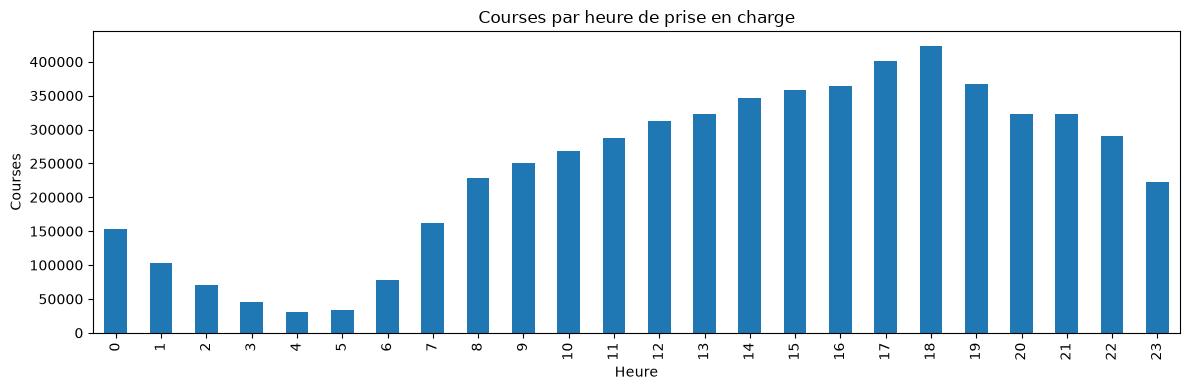

,pickup_hour,courses,panier_moyen
18,18,423668,26.88
17,17,400748,28.16
19,19,367559,27.57


In [9]:
# Heures de pointe
peak = spark.sql(f"""
SELECT pickup_hour, COUNT(*) AS courses, ROUND(AVG(total_amount), 2) AS panier_moyen
FROM {T_GOLD_FACT_TRIPS} GROUP BY pickup_hour ORDER BY pickup_hour
""").toPandas()

import matplotlib.pyplot as plt
ax = peak.plot.bar(x="pickup_hour", y="courses", figsize=(12, 4), legend=False, title="Courses par heure de prise en charge")
ax.set_xlabel("Heure"); ax.set_ylabel("Courses"); plt.tight_layout(); plt.show()
peak.sort_values("courses", ascending=False).head(3)

In [10]:
# Repartition des moyens de paiement
spark.sql(f"""
SELECT CASE payment_type WHEN 0 THEN 'Flex Fare' WHEN 1 THEN 'Carte' WHEN 2 THEN 'Especes'
                         WHEN 3 THEN 'Gratuit' WHEN 4 THEN 'Litige' ELSE 'Autre' END AS paiement,
       COUNT(*) AS courses,
       ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct
FROM {T_GOLD_FACT_TRIPS} GROUP BY ALL ORDER BY courses DESC
""").show()

+---------+-------+-----+
| paiement|courses|  pct|
+---------+-------+-----+
|    Carte|4620551|80.06|
|  Especes| 819482|14.20|
|Flex Fare| 264116| 4.58|
|   Litige|  46310| 0.80|
|  Gratuit|  21161| 0.37|
+---------+-------+-----+



In [11]:
# Aeroports vs reste de la ville
spark.sql(f"""
SELECT CASE WHEN z.is_airport THEN 'Aeroport' ELSE 'Ville' END AS origine,
       COUNT(*) AS courses,
       ROUND(AVG(f.total_amount), 2)  AS panier_moyen,
       ROUND(AVG(f.trip_distance), 2) AS distance_moy,
       ROUND(SUM(f.total_amount) * 100.0 / SUM(SUM(f.total_amount)) OVER (), 1) AS pct_ca
FROM {T_GOLD_FACT_TRIPS} f JOIN {T_GOLD_DIM_ZONE} z ON f.pu_zone_key = z.zone_key
GROUP BY ALL
""").show()

+--------+-------+------------+------------+------+
| origine|courses|panier_moyen|distance_moy|pct_ca|
+--------+-------+------------+------------+------+
|Aeroport| 432667|       75.31|       13.39|  20.7|
|   Ville|5338953|       23.39|        2.44|  79.3|
+--------+-------+------------+------------+------+



In [12]:
# Semaine vs week-end
spark.sql(f"""
SELECT CASE WHEN is_weekend THEN 'Week-end' ELSE 'Semaine' END AS periode,
       ROUND(AVG(total_trips)) AS courses_par_jour,
       ROUND(AVG(avg_fare), 2) AS panier_moyen,
       ROUND(AVG(card_tip_rate_pct), 2) AS taux_pourboire_carte
FROM {T_GOLD_DAILY_KPIS} GROUP BY ALL
""").show()

+--------+----------------+------------+--------------------+
| periode|courses_par_jour|panier_moyen|taux_pourboire_carte|
+--------+----------------+------------+--------------------+
| Semaine|         96600.0|       27.77|               22.69|
|Week-end|         95077.0|       26.25|               22.32|
+--------+----------------+------------+--------------------+



In [13]:
# Top 5 trajets (zone de depart -> zone d'arrivee)
spark.sql(f"""
SELECT pu.zone AS depart, do.zone AS arrivee, COUNT(*) AS courses, ROUND(AVG(f.total_amount), 2) AS panier_moyen
FROM {T_GOLD_FACT_TRIPS} f
JOIN {T_GOLD_DIM_ZONE} pu ON f.pu_zone_key = pu.zone_key
JOIN {T_GOLD_DIM_ZONE} do ON f.do_zone_key = do.zone_key
GROUP BY ALL ORDER BY courses DESC LIMIT 5
""").show(truncate=False)

+---------------------+---------------------+-------+------------+
|depart               |arrivee              |courses|panier_moyen|
+---------------------+---------------------+-------+------------+
|Upper East Side South|Upper East Side North|42429  |15.68       |
|Upper East Side North|Upper East Side South|37546  |16.09       |
|Upper East Side North|Upper East Side North|30019  |13.26       |
|Upper East Side South|Upper East Side South|27497  |13.86       |
|Midtown Center       |Upper East Side South|20245  |17.07       |
+---------------------+---------------------+-------+------------+



## Conclusion — Gold Layer

| Table | Type | Contenu |
|---|---|---|
| `gold.fact_trips` | Fait | 1 ligne = 1 course valide, avec clés vers les dimensions et mesures |
| `gold.dim_zone` | Dimension | 265 zones + indicateur aéroport |
| `gold.dim_date` | Dimension | Calendrier (jour, mois, week-end…) |
| `gold.kpi_daily` | Agrégat | KPIs par jour (courses, CA, panier moyen, taux de pourboire…) |
| `gold.kpi_pickup_zone` | Agrégat | KPIs par zone de prise en charge |

Ces tables alimentent le **dashboard** (Phase 11) et sont contrôlées par le **framework Data Quality** (Phase 6).